# KadeMila – Next-month food price forecasts for 36 Sri Lankan markets
### Ensemble Learning Dashboard

**Name:** O.P.N.Y.K Bandara  
**Index:** 224021T


**🔗 Live dashboard:** [https://kademila.streamlit.app](https://kademila.streamlit.app)

**Contents**
1. Problem & innovation
2. Data source
3. Data cleaning & feature engineering
4. EDA
5. Modelling setup
6. Baselines
7. Bagging
8. Boosting
9. Stacking
10. Hybrid models (RF + ANN, RF + ARIMA)
11. Model comparison
12. Explainability (SHAP)
13. Research discussion
14. Dashboard
15. Conclusion & limitations
16. References

**Key result:** stacking (RF + XGBoost + LightGBM + CatBoost → Ridge) is the best model on 2025 prices and the only one that beats the naive
"same as last month" forecast on every metric; on big price moves (> 20 %) it cuts the error by about 21 %.

## 1. Problem & innovation
After the 2022 economic crisis, food prices in Sri Lanka became volatile and uneven: the same kilo of rice or dhal can cost very
different amounts in different districts. Families, small traders and aid programmes (Aswesuma, WFP) have no simple tool that
says whether a price is fair or where it is heading. **KadeMila** uses ensemble learning on official WFP / DCS
market data to forecast next month's retail price of 33 food items in 36 markets, and shows which districts pay more than the
national level.

**What is new**
1. **"Is this price fair?" check** – enter market, item and quoted price; the dashboard shows the expected price and whether the quote is high or low.
2. **Regional gap feature** (`rel_to_national`) – how much dearer/cheaper a market is than the national median.
3. **Early warning** – markets and items predicted to rise (or fall) more than 10 % next month.
4. **Crisis lens** – RF + ARIMA hybrid on 20 years of Colombo rice prices, including the 2022 shock.

### Setup
Run once if libraries are missing:
```
pip install -r requirements-notebook.txt
```

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# same seed everywhere so the results can be reproduced
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

# all charts are also saved here (I reuse them in the slides)
FIG = Path("reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

## 2. Data source
* **Dataset:** WFP *Sri Lanka – Food Prices* on the Humanitarian Data Exchange (HDX):
  https://data.humdata.org/dataset/wfp-food-prices-for-sri-lanka
* **Original sources:** Department of Census and Statistics (DCS), HARTI, CEPETCO and WFP market surveys.
* **Licence:** CC BY-IGO. Downloaded once as CSV (`data/raw/wfp_food_prices_lka.csv`), so no scraping is needed and the notebook runs offline.
* **Columns:** date, province (admin1), district (admin2), market, lat/lon, category, commodity, unit, price type, price (LKR).

In [2]:
raw = pd.read_csv("data/raw/wfp_food_prices_lka.csv")

# the HDX file sometimes has a second header row starting with "#", remove it
raw = raw[~raw["date"].astype(str).str.startswith("#")]
raw["date"] = pd.to_datetime(raw["date"])

print("Rows:", len(raw))
print("Markets:", raw["market"].nunique())
print("Commodities:", raw["commodity"].nunique())
print("Period:", raw["date"].min().date(), "to", raw["date"].max().date())
raw.head()

Rows: 34262 | Markets: 44 | Commodities: 42 | Period: 2004-01-15 to 2025-09-15


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2004-01-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Rice (red nadu),157,KG,actual,Retail,LKR,32.71,0.33
1,2004-01-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Wheat flour,58,KG,actual,Retail,LKR,26.66,0.27
2,2004-02-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Rice (red nadu),157,KG,actual,Retail,LKR,33.62,0.34
3,2004-02-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Wheat flour,58,KG,actual,Retail,LKR,26.71,0.27
4,2004-03-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Rice (red nadu),157,KG,actual,Retail,LKR,32.92,0.34


## 3. Data cleaning & feature engineering
Key decisions:
* Retail prices only; drop the "National Average" pseudo-market, fuel (non-food) and commodities with < 100 rows.
* Prices are already numeric LKR (no text cleaning needed).
* Outliers: crisis spikes are real, so we only drop data-entry errors (> 4x or < 1/4 of that month's national median).
* **Lag features use only last month's information** → no data leakage.
* Modelling window starts June 2023 (when 34–36 markets are surveyed every month). **Train: Jun 2023 – Dec 2024, Test: Jan – Sep 2025.**

In [3]:
# folders for the cleaned files (the notebook is run from the project folder)
ROOT = Path.cwd()
RAW = ROOT / "data" / "raw" / "wfp_food_prices_lka.csv"
OUT = ROOT / "data" / "processed"
OUT.mkdir(parents=True, exist_ok=True)

In [4]:
# Step 1: load the raw file again for cleaning
df = pd.read_csv(RAW)
df = df[~df["date"].astype(str).str.startswith("#")]
df["date"] = pd.to_datetime(df["date"])
df["price"] = pd.to_numeric(df["price"], errors="coerce")   # prices are already numbers in LKR
print("raw rows:", len(df))

raw rows: 34262


In [5]:
# Step 2: keep only the rows I need
df = df[df["pricetype"] == "Retail"]
df = df[df["currency"] == "LKR"]
df = df[df["market"] != "National Average"]   # this is an average, not a real market
df = df[df["category"] != "non-food"]         # fuel prices, not food
df = df.dropna(subset=["price"])
df = df[df["price"] > 0]

# drop items with very few rows, there is not enough data to learn from them
counts = df["commodity"].value_counts()
items_to_keep = counts[counts >= 100].index
df = df[df["commodity"].isin(items_to_keep)]

# WFP puts every price on the 15th of the month, so I use the first day of the month as the key
df["month"] = df["date"].dt.to_period("M").dt.to_timestamp()
df = df.drop_duplicates(["month", "market", "commodity"], keep="last")
print("after filtering:", len(df))

after filtering: 32910


In [6]:
# Step 3: missing values
# province / district / lat / lon were only missing for the "National Average" rows (already removed),
# but just in case I fill any gaps from the markets file
markets = pd.read_csv(ROOT / "data" / "raw" / "wfp_markets_lka.csv")
markets = markets[~markets["market_id"].astype(str).str.startswith("#")]
markets["market_id"] = markets["market_id"].astype(int)
markets["latitude"] = markets["latitude"].astype(float)
markets["longitude"] = markets["longitude"].astype(float)
markets = markets[["market_id", "admin1", "admin2", "latitude", "longitude"]]

df = df.merge(markets, on="market_id", how="left", suffixes=("", "_mk"))
for col in ["admin1", "admin2", "latitude", "longitude"]:
    df[col] = df[col].fillna(df[col + "_mk"])
df = df.drop(columns=["admin1_mk", "admin2_mk", "latitude_mk", "longitude_mk"])
df["admin1"] = df["admin1"].fillna("Unknown")
df["admin2"] = df["admin2"].fillna("Unknown")

print("missing values left:")
print(df[["admin1", "admin2", "latitude", "longitude", "price"]].isna().sum())

missing values left:
 admin1       0
admin2       0
latitude     0
longitude    0
price        0


In [7]:
# Step 4: outliers
# The big jumps during the crisis are real, so I don't cut them.
# I only remove prices that look like typing mistakes:
# more than 4x or less than 1/4 of the national median for that item in that month.
median_price = df.groupby(["commodity", "month"])["price"].transform("median")
ratio = df["price"] / median_price
bad = (ratio > 4) | (ratio < 0.25)
print("outliers dropped:", bad.sum())
df = df[~bad].copy()

columns = ["month", "admin1", "admin2", "market", "latitude", "longitude",
           "category", "commodity", "unit", "price"]
clean = df[columns].sort_values(["market", "commodity", "month"]).reset_index(drop=True)
clean.to_csv(OUT / "prices_clean.csv", index=False)

outliers dropped: 3


In [8]:
# Step 5: features
# Idea: predict this month's price using only what we already knew at the end of last month.

# I also add one empty row for the month after the data ends (October 2025),
# so the dashboard can forecast it with exactly the same feature code
NEXT_MONTH = clean["month"].max() + pd.DateOffset(months=1)
last_rows = clean.groupby(["market", "commodity"]).tail(1)
recent = last_rows[last_rows["month"] >= NEXT_MONTH - pd.DateOffset(months=6)]
future = recent.copy()
future["month"] = NEXT_MONTH
future["price"] = np.nan
clean = pd.concat([clean, future]).sort_values(["market", "commodity", "month"]).reset_index(drop=True)

g = clean.groupby(["market", "commodity"], sort=False)

# previous prices for the same market and item
clean["lag_1"] = g["price"].shift(1)
clean["lag_2"] = g["price"].shift(2)
clean["lag_3"] = g["price"].shift(3)

# how many months ago the last price was recorded (some months are missing)
month_number = clean["month"].dt.year * 12 + clean["month"].dt.month
prev_month = g["month"].shift(1)
clean["months_since_last"] = month_number - (prev_month.dt.year * 12 + prev_month.dt.month)

# 3-month average and spread, using past months only
clean["roll_mean_3"] = g["price"].transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
clean["roll_std_3"] = g["price"].transform(lambda s: s.shift(1).rolling(3, min_periods=2).std())
clean["pct_change_1"] = clean["lag_1"] / clean["lag_2"] - 1

# national median of the item last month, and how dear this market is compared to it
nat = clean.groupby(["commodity", "month"])["price"].median().reset_index()
nat.columns = ["commodity", "month", "nat_median_lag1"]
nat["month"] = nat["month"] + pd.DateOffset(months=1)   # move forward one month = "last month's value"
clean = clean.merge(nat, on=["commodity", "month"], how="left")
clean["rel_to_national"] = clean["lag_1"] / clean["nat_median_lag1"]

# national trend last month, and the change in the same month last year
nat_table = clean.groupby(["commodity", "month"])["price"].median().unstack(0).asfreq("MS")
nat_change = (nat_table.shift(1) / nat_table.shift(2) - 1).stack().rename("nat_change_1").reset_index()
ly_change = (nat_table.shift(11) / nat_table.shift(12) - 1).stack().rename("ly_change").reset_index()
clean = clean.merge(nat_change, on=["month", "commodity"], how="left")
clean = clean.merge(ly_change, on=["month", "commodity"], how="left")

# is last month's price above or below its own 3-month average?
clean["lag1_vs_roll"] = clean["lag_1"] / clean["roll_mean_3"] - 1

# month of the year (New Year in April, Maha / Yala harvest seasons)
clean["year"] = clean["month"].dt.year
clean["month_num"] = clean["month"].dt.month
clean["month_sin"] = np.sin(2 * np.pi * clean["month_num"] / 12)
clean["month_cos"] = np.cos(2 * np.pi * clean["month_num"] / 12)

In [9]:
# Step 6: build the modelling table
def fill_features(d):
    d = d.copy()
    d["roll_std_3"] = d["roll_std_3"].fillna(0)
    d["lag_2"] = d["lag_2"].fillna(d["lag_1"])
    d["lag_3"] = d["lag_3"].fillna(d["lag_1"])
    d["pct_change_1"] = d["pct_change_1"].fillna(0)
    d["nat_median_lag1"] = d["nat_median_lag1"].fillna(d["lag_1"])
    d["rel_to_national"] = d["rel_to_national"].fillna(1)
    d["nat_change_1"] = d["nat_change_1"].fillna(0)
    d["ly_change"] = d["ly_change"].fillna(0)
    d["lag1_vs_roll"] = d["lag1_vs_roll"].fillna(0)
    # if the last price is more than 6 months old it doesn't say much, so drop those rows
    return d[d["months_since_last"] <= 6]

# Most markets are only surveyed every month from June 2023, so I start there
model = clean[(clean["month"] >= "2023-06-01") & clean["price"].notna()]
model = model.dropna(subset=["lag_1"])   # need at least one earlier price
model = fill_features(model)

# time-based split: train on 2023-2024, test on 2025 (no shuffling)
model["split"] = np.where(model["month"] >= "2025-01-01", "test", "train")
model.to_csv(OUT / "model_table.csv", index=False)

print("model table:", model.shape)
print(model["split"].value_counts())
print("markets:", model["market"].nunique(), "| commodities:", model["commodity"].nunique())

# rows for next month (used by the dashboard's prediction form)
nxt = clean[clean["price"].isna()].dropna(subset=["lag_1"])
nxt = fill_features(nxt)
nxt.to_csv(OUT / "next_month_features.csv", index=False)
print("next-month rows:", len(nxt), "for", NEXT_MONTH.strftime("%B %Y"))


model table: (27510, 27)
split
train    18449
test      9061
markets: 36 | commodities: 33
next-month rows: 1141 for October 2025


In [10]:
# Step 7: one long monthly series for the RF + ARIMA part (white rice in Colombo)
is_rice = (clean["market"] == "Colombo City") & (clean["commodity"] == "Rice (white)") & clean["price"].notna()
rice = clean[is_rice].set_index("month")["price"].asfreq("MS")
print("rice series months:", len(rice), "| missing months filled:", rice.isna().sum())
rice = rice.interpolate(method="time")
rice.rename("price").to_frame().to_csv(OUT / "rice_colombo_monthly.csv")


rice series months: 231 | gaps filled by interpolation: 11


In [11]:
model_df = pd.read_csv("data/processed/model_table.csv", parse_dates=["month"])
clean_df = pd.read_csv("data/processed/prices_clean.csv", parse_dates=["month"])
rice = pd.read_csv("data/processed/rice_colombo_monthly.csv", parse_dates=["month"], index_col="month")["price"]
model_df.head()

,month,admin1,admin2,market,latitude,longitude,category,commodity,unit,price,lag_1,lag_2,lag_3,months_since_last,roll_mean_3,roll_std_3,pct_change_1,nat_median_lag1,rel_to_national,nat_change_1,ly_change,lag1_vs_roll,year,month_num,month_sin,month_cos,split
0,2023-07-01,Eastern,Ampara,Ampara,7.28,81.67,vegetables and fruits,Bananas,KG,152.00,163.12,163.12,163.12,1.0,163.120000,0.000000,0.000000,146.5,1.113447,0.753021,0.168769,0.000000,2023,7,-0.500000,-8.660254e-01,train
1,2023-08-01,Eastern,Ampara,Ampara,7.28,81.67,vegetables and fruits,Bananas,KG,160.00,152.00,163.12,152.00,1.0,157.560000,7.863027,-0.068171,155.6,0.976864,0.062116,0.058099,-0.035288,2023,8,-0.866025,-5.000000e-01,train
2,2023-09-01,Eastern,Ampara,Ampara,7.28,81.67,vegetables and fruits,Bananas,KG,199.17,160.00,152.00,163.12,1.0,158.373333,5.735689,0.052632,201.5,0.794045,0.294987,0.031193,0.010271,2023,9,-1.000000,-1.836970e-16,train
3,2023-10-01,Eastern,Ampara,Ampara,7.28,81.67,vegetables and fruits,Bananas,KG,188.67,199.17,160.00,152.00,1.0,170.390000,25.243144,0.244812,213.0,0.935070,0.057072,-0.054698,0.168907,2023,10,-0.866025,5.000000e-01,train
4,2023-11-01,Eastern,Ampara,Ampara,7.28,81.67,vegetables and fruits,Bananas,KG,185.00,188.67,199.17,160.00,1.0,182.613333,20.275222,-0.052719,207.6,0.908815,-0.025352,-0.100438,0.033167,2023,11,-0.500000,8.660254e-01,train


## 4. Exploratory data analysis (EDA)

### 4.1 Data coverage over time

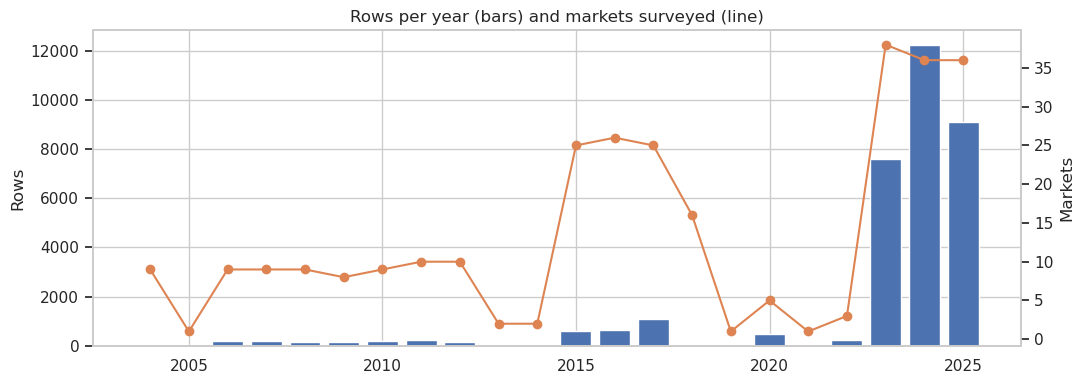

In [12]:
retail = raw[raw["pricetype"] == "Retail"]
cov = retail.groupby(retail["date"].dt.year).agg(rows=("price", "size"), markets=("market", "nunique"))

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(cov.index, cov["rows"], color="#4C72B0")
ax.set_ylabel("Rows")
ax.set_title("Rows per year (bars) and markets surveyed (line)")

ax2 = ax.twinx()
ax2.plot(cov.index, cov["markets"], color="#DD8452", marker="o")
ax2.set_ylabel("Markets")
ax2.grid(False)

plt.tight_layout()
plt.savefig(FIG / "eda_01_coverage.png", dpi=120)
plt.show()

**Insight:** before 2023 only 1–10 markets were surveyed in most years; from mid-2023 WFP covers 34–36 markets every month. This is why we train on Jun 2023 – Dec 2024 and test on Jan – Sep 2025, not on 2004–2021.

### 4.2 The 2022 crisis: Colombo white rice, 2006–2025

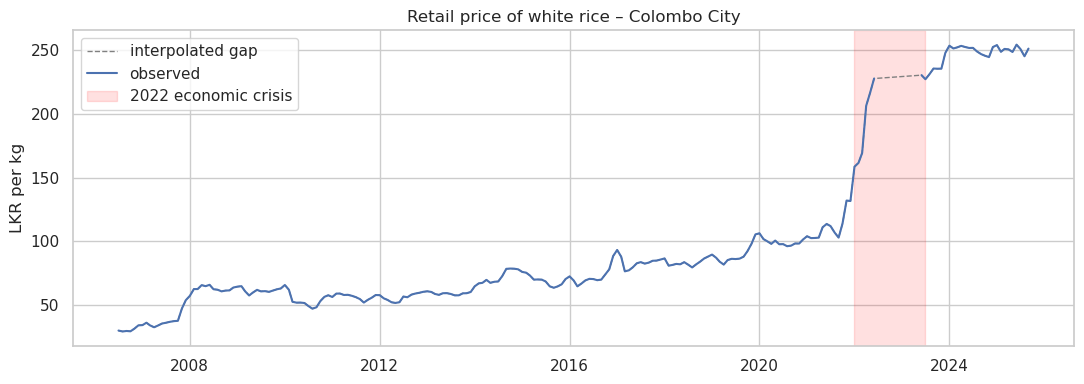

month
2019-12-31     89.3
2020-12-31     99.5
2021-12-31    111.4
2022-12-31    209.1
2023-12-31    232.4
2024-12-31    250.1
2025-12-31    250.2
Freq: YE-DEC


In [13]:
# real observations in blue, months I filled in (interpolated) as a dashed grey line
is_rice = (clean_df["market"] == "Colombo City") & (clean_df["commodity"] == "Rice (white)")
observed = clean_df[is_rice].set_index("month")["price"].reindex(rice.index)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(rice.index, rice.values, color="grey", ls="--", lw=1, label="interpolated gap")
ax.plot(observed.index, observed.values, color="#4C72B0", label="observed")
ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2023-06-30"), color="red", alpha=0.12, label="2022 economic crisis")
ax.set_ylabel("LKR per kg")
ax.set_title("Retail price of white rice – Colombo City")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "eda_02_rice_crisis.png", dpi=120)
plt.show()

# yearly average price
print(rice.resample("YE").mean().round(1).loc["2019":])

**Insight:** white rice cost about Rs 100–110/kg in 2020–21, jumped to about Rs 230 in 2022 and settled near Rs 250 from 2024: the crisis roughly **doubled** the price, and it never came back down. (The dashed part is a stretch of missing months filled by interpolation.)

### 4.3 Price distribution: raw vs log

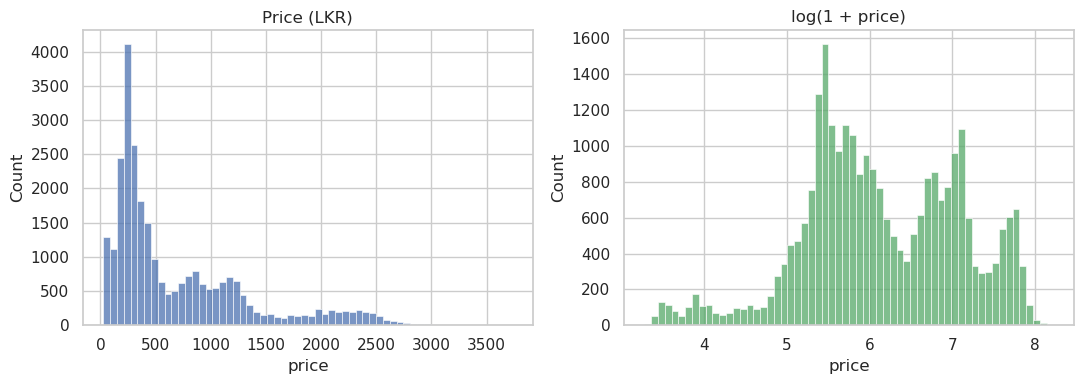

Skewness raw: 1.42 | log: -0.21


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(model_df["price"], bins=60, ax=axes[0])
axes[0].set_title("Price (LKR)")
sns.histplot(np.log1p(model_df["price"]), bins=60, ax=axes[1], color="#55A868")
axes[1].set_title("log(1 + price)")
plt.tight_layout()
plt.savefig(FIG / "eda_03_price_dist.png", dpi=120)
plt.show()

print("Skewness raw:", round(model_df["price"].skew(), 2))
print("Skewness log:", round(np.log1p(model_df["price"]).skew(), 2))

**Insight:** raw prices are right-skewed (Rs 20 eggs to Rs 3,000+ fish), but log prices are close to symmetric, so the models train on log(price) and we convert back to LKR for the metrics.

### 4.4 Price index by food category (Jun 2023 = 100)

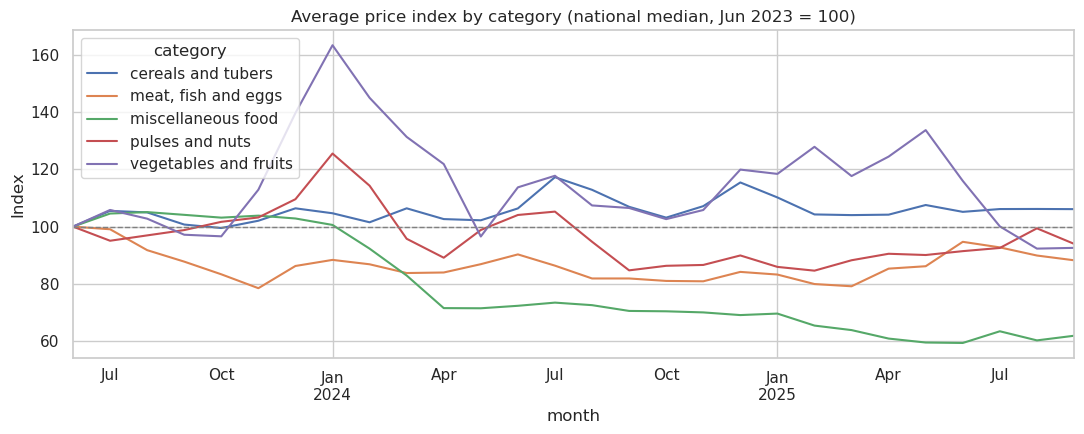

In [15]:
# price index: national median of each item, divided by its June 2023 value
w = clean_df[clean_df["month"] >= "2023-06-01"]
idx = w.groupby(["commodity", "month"])["price"].median().reset_index()
idx["base"] = idx.groupby("commodity")["price"].transform("first")
idx["index"] = idx["price"] / idx["base"] * 100
idx = idx.merge(w[["commodity", "category"]].drop_duplicates(), on="commodity")

# average the item indexes inside each category
cat_idx = idx.groupby(["category", "month"])["index"].mean().unstack(0)
ax = cat_idx.plot(figsize=(11, 4.5), title="Average price index by category (national median, Jun 2023 = 100)")
ax.axhline(100, color="grey", ls="--", lw=1)
ax.set_ylabel("Index")
plt.tight_layout()
plt.savefig(FIG / "eda_04_category_index.png", dpi=120)
plt.show()

**Insight:** vegetables & fruits swing the most (index peaked around 160 in Dec 2023), cereals stay close to 100–115, and dried chilli (the only 'miscellaneous' item) and pulses got cheaper after the crisis.

### 4.5 Which items are most volatile?

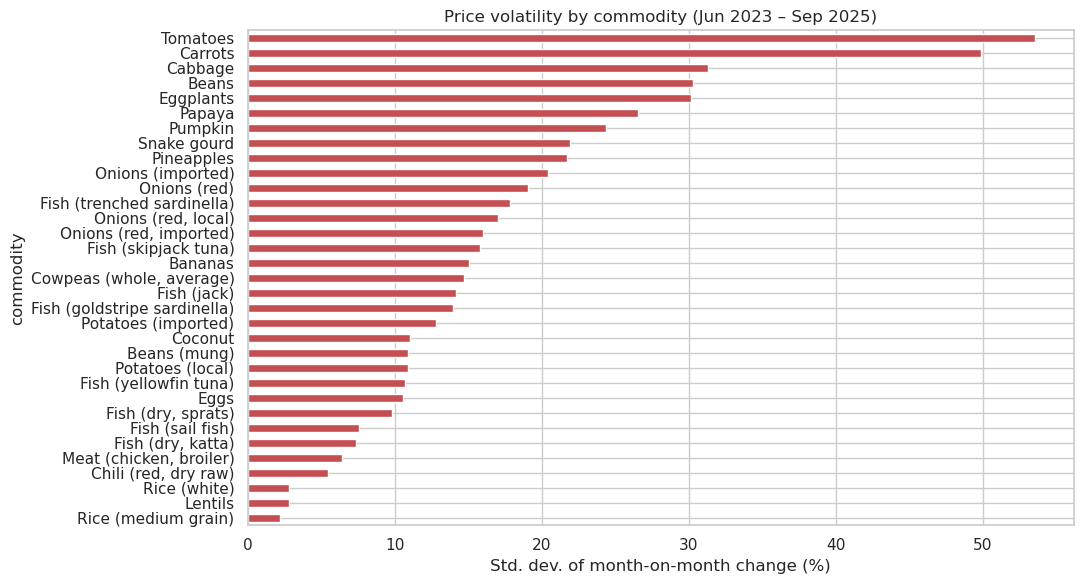

In [16]:
# month-on-month % change for every market and item, then the spread per item
mom = w.sort_values("month").groupby(["market", "commodity"])["price"].pct_change()
w_mom = w.copy()
w_mom["mom"] = mom
vol = w_mom.groupby("commodity")["mom"].std() * 100
vol = vol.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(11, 6))
vol.plot.barh(ax=ax, color="#C44E52")
ax.invert_yaxis()
ax.set_xlabel("Std. dev. of month-on-month change (%)")
ax.set_title("Price volatility by commodity (Jun 2023 – Sep 2025)")
plt.tight_layout()
plt.savefig(FIG / "eda_05_volatility.png", dpi=120)
plt.show()

**Insight:** tomatoes and carrots move about 50 % month to month, while rice and lentils move under 3 %. Errors will be largest on upcountry vegetables, so we report results per category too.

### 4.6 Seasonality: average month-on-month change by calendar month

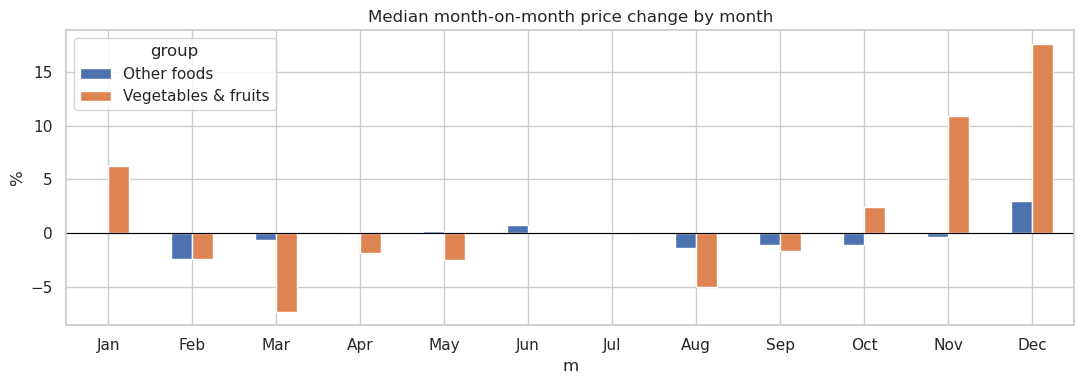

In [17]:
s = w.copy()
s["mom"] = mom * 100
s["m"] = s["month"].dt.month
s["group"] = np.where(s["category"] == "vegetables and fruits", "Vegetables & fruits", "Other foods")
season = s.groupby(["m", "group"])["mom"].median().unstack()

ax = season.plot.bar(figsize=(11, 4), title="Median month-on-month price change by month")
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"], rotation=0)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("%")
plt.tight_layout()
plt.savefig(FIG / "eda_06_seasonality.png", dpi=120)
plt.show()

**Insight:** vegetable prices tend to rise in Nov–Jan (north-east monsoon rains and festive demand) and fall in Mar and Aug (harvests). We only have about two years of seasons, so this is a tendency, not a rule; it is why the month features are included.

### 4.7 Regional price gaps by province

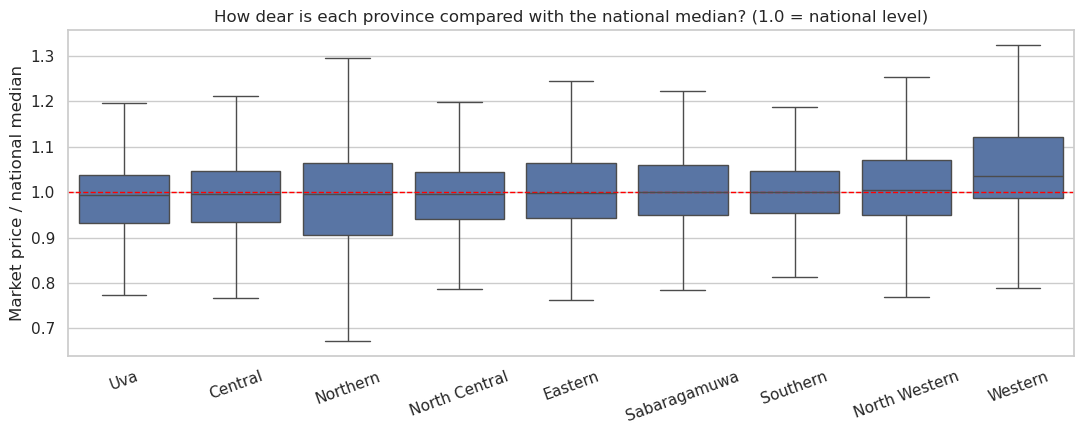

admin1
Uva              0.993
Central          0.996
Northern         0.996
North Central    0.997
Eastern          0.998
Sabaragamuwa     1.000
Southern         1.000
North Western    1.004
Western          1.034


In [18]:
province_median = model_df.groupby("admin1")["rel_to_national"].median().sort_values()

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=model_df, x="admin1", y="rel_to_national", order=province_median.index, showfliers=False, ax=ax)
ax.axhline(1, color="red", ls="--", lw=1)
ax.set_xlabel("")
ax.set_ylabel("Market price / national median")
ax.set_title("How dear is each province compared with the national median? (1.0 = national level)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(FIG / "eda_07_regional_gap.png", dpi=120)
plt.show()

print(province_median.round(3))

**Insight:** Western Province (Colombo, Gampaha, Kalutara) is the dearest, about 3 % above the national median on average. The Northern Province has the widest spread, meaning some northern markets are far above and others far below national prices.

### 4.8 Last month's price vs this month's price

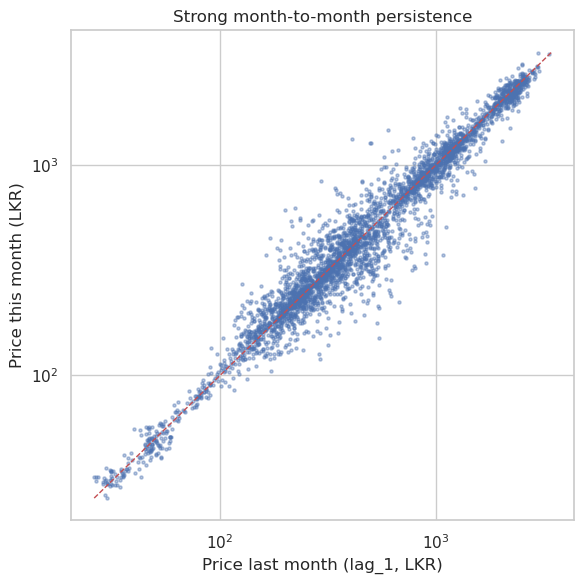

Correlation log(lag_1) vs log(price): 0.979


In [19]:
sample = model_df.sample(4000, random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(sample["lag_1"], sample["price"], s=5, alpha=0.4)
low = min(sample["lag_1"].min(), sample["price"].min())
high = max(sample["lag_1"].max(), sample["price"].max())
ax.plot([low, high], [low, high], "r--", lw=1)   # points on this line = price did not change
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Price last month (lag_1, LKR)")
ax.set_ylabel("Price this month (LKR)")
ax.set_title("Strong month-to-month persistence")
plt.tight_layout()
plt.savefig(FIG / "eda_08_lag_scatter.png", dpi=120)
plt.show()

corr = np.corrcoef(np.log(model_df["lag_1"]), np.log(model_df["price"]))[0, 1]
print("Correlation log(lag_1) vs log(price):", round(corr, 4))

**Insight:** this month's price is very close to last month's (correlation of the logs about 0.98). So a naive 'same as last month' forecast is already strong, and our models must **beat this naive baseline** to be useful.

### 4.9 Correlation between numeric features

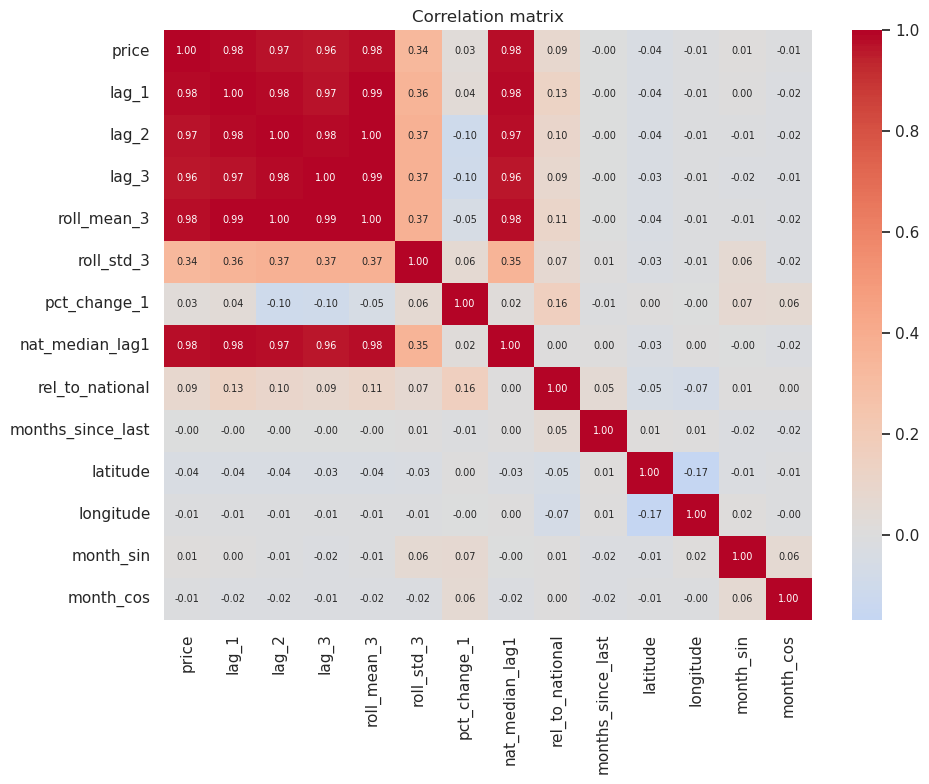

In [20]:
num = ["price", "lag_1", "lag_2", "lag_3", "roll_mean_3", "roll_std_3", "pct_change_1", "nat_median_lag1",
       "rel_to_national", "months_since_last", "latitude", "longitude", "month_sin", "month_cos"]

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(model_df[num].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.savefig(FIG / "eda_09_corr.png", dpi=120)
plt.show()

**Insight:** the lag features, rolling mean and national median are almost perfectly correlated with each other (about 0.97–0.99). That is fine for tree ensembles, but it is why the linear baseline uses Ridge regularisation. Location and month features have weak *linear* correlation, but trees can still use them in interactions (e.g. carrots in Nuwara Eliya in December).

## 5. Modelling setup
* **Task:** predict this month's retail price (LKR) for a market × commodity, using only information known at the end of last month.
* **Target:** `log(price / last month's price)`, i.e. the model predicts the **% change**, then we convert back to LKR.
  (In a quick test, predicting log(price) directly lost to the naive forecast; predicting the change works better because trees cannot extrapolate to new price levels.)
* **Split (time-based, no shuffling):** train Jun 2023 – Dec 2024, test Jan – Sep 2025.
* **Cross-validation:** expanding-window, month-based folds inside the training period (validate on Apr–Jun, Jul–Sep, Oct–Dec 2024).
* **Metrics:** MAE, RMSE, R² and MAPE, all in LKR on the 2025 test set. `random_state = 42` everywhere.

In [21]:
import json
import joblib
import matplotlib.dates
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.model_selection import RandomizedSearchCV, KFold, cross_val_predict
from sklearn.linear_model import RidgeCV, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, BaggingRegressor, ExtraTreesRegressor, StackingRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# my helper functions and small model classes are in src/kademila_utils.py
# (the dashboard needs the same code to load the saved models)
from src.kademila_utils import (CAT_COLS, NUM_COLS, FEATURES, make_target, to_price, regression_metrics,
                                set_categories, CatBoostWrap, RFANNResidualHybrid, WeightedBlend)

MODELS = Path("models")
MODELS.mkdir(exist_ok=True)
REPORTS = Path("reports")
REPORTS.mkdir(exist_ok=True)

data = model_df.sort_values(["month", "market", "commodity"]).reset_index(drop=True)

# fixed list of categories so train, test and the dashboard all use the same codes
CATEGORIES = {}
for col in CAT_COLS:
    CATEGORIES[col] = sorted(data[col].astype(str).unique())
data = set_categories(data, CATEGORIES)

train = data[data["split"] == "train"].reset_index(drop=True)
test = data[data["split"] == "test"].reset_index(drop=True)
X_train = train[FEATURES]
X_test = test[FEATURES]
y_train = make_target(train)        # log(price / last month's price)
y_test_price = test["price"].values # real prices in LKR, used for the final scores

print("Train:", X_train.shape, train["month"].min().date(), "to", train["month"].max().date())
print("Test :", X_test.shape, test["month"].min().date(), "to", test["month"].max().date())

# Cross-validation that respects time: train on earlier months, check on the next 3 months.
def month_folds(months, starts=("2024-04-01", "2024-07-01", "2024-10-01"), length=3):
    folds = []
    for start in pd.to_datetime(list(starts)):
        end = start + pd.DateOffset(months=length)
        train_idx = np.where(months < start)[0]
        val_idx = np.where((months >= start) & (months < end))[0]
        folds.append((train_idx, val_idx))
    return folds

CV = month_folds(train["month"])
for i, (a, b) in enumerate(CV, 1):
    first = train["month"].iloc[b].min().date()
    last = train["month"].iloc[b].max().date()
    print(f"fold {i}: train {len(a)} rows | validate {len(b)} rows ({first} to {last})")

# trees only need the categories turned into numbers
tree_pre = ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT_COLS)],
                             remainder="passthrough")
# Ridge and the neural network need one-hot categories and scaled numbers
lin_pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS)],
                            remainder=StandardScaler())

results = []
test_preds = {}
fitted = {}

# saves the test scores (in LKR) of one model
def record(name, family, model, train_time, pred_log_change=None, pred_price=None):
    if pred_price is None:
        pred_price = to_price(pred_log_change, test)
    test_preds[name] = pred_price
    fitted[name] = model
    scores = regression_metrics(y_test_price, pred_price)
    row = {"Model": name, "Family": family}
    row.update(scores)
    row["Train time (s)"] = train_time
    results.append(row)
    print(f"{name:<28} MAE {scores['MAE']:8.2f} | RMSE {scores['RMSE']:8.2f} | "
          f"R2 {scores['R2']:.4f} | MAPE {scores['MAPE_%']:.2f}% | {train_time:.1f}s")

# light tuning with RandomizedSearchCV on the time-based folds, then score on the test set
def tune(name, family, estimator, params, n_iter):
    start = time.time()
    search = RandomizedSearchCV(estimator, params, n_iter=n_iter, cv=CV, scoring="neg_mean_absolute_error",
                                random_state=RANDOM_STATE, n_jobs=1, refit=True)
    search.fit(X_train, y_train)
    print("  best CV MAE (log-change):", round(-search.best_score_, 4))
    print("  best params:", search.best_params_)
    best = search.best_estimator_
    record(name, family, best, time.time() - start, best.predict(X_test))
    return best

Train: (18449, 23) 2023-06-01 to 2024-12-01
Test : (9061, 23) 2025-01-01 to 2025-09-01
fold 1: train  9381 rows | validate 2962 rows (2024-04-01 to 2024-06-01)
fold 2: train 12343 rows | validate 2988 rows (2024-07-01 to 2024-09-01)
fold 3: train 15331 rows | validate 3118 rows (2024-10-01 to 2024-12-01)


## 6. Baselines
* **Naive:** "price this month = price last month". Any useful model must beat this.
* **Ridge regression:** a regularised linear model (one-hot categories + scaled numbers).

In [22]:
# Baseline 1: next month's price = this month's price
record("Naive (last month)", "Baseline", None, 0.0, pred_price=test["lag_1"].values)

# Baseline 2: Ridge regression
start = time.time()
ridge = Pipeline([("pre", lin_pre), ("model", RidgeCV(alphas=np.logspace(-2, 3, 12)))])
ridge.fit(X_train, y_train)
record("Ridge (linear)", "Baseline", ridge, time.time() - start, ridge.predict(X_test))

Naive (last month)           MAE    65.41 | RMSE   112.19 | R2 0.9704 | MAPE 12.19% | 0.0s


Ridge (linear)               MAE    88.58 | RMSE   146.26 | R2 0.9497 | MAPE 13.45% | 0.5s


## 7. Bagging: Random Forest, Bagging, Extra Trees
Bagging trains many trees **independently** on bootstrap samples and averages them, which **reduces variance**.
Random Forest also picks a random subset of features at each split, so the trees are less alike.

In [23]:
# Random Forest (with light tuning)
rf_params = {
    "model__n_estimators": [200, 300],
    "model__max_depth": [None, 20, 30],
    "model__min_samples_leaf": [1, 3, 5, 10],
    "model__max_features": [0.3, 0.5, 0.8],
}
rf_pipe = Pipeline([("pre", tree_pre), ("model", RandomForestRegressor(n_jobs=-1, random_state=RANDOM_STATE))])
rf = tune("Random Forest", "Bagging", rf_pipe, rf_params, n_iter=6)

# plain bagging of decision trees
start = time.time()
tree = DecisionTreeRegressor(min_samples_leaf=5, random_state=RANDOM_STATE)
bag = Pipeline([("pre", tree_pre),
                ("model", BaggingRegressor(tree, n_estimators=100, max_samples=0.8, n_jobs=-1, random_state=RANDOM_STATE))])
bag.fit(X_train, y_train)
record("Bagging (decision trees)", "Bagging", bag, time.time() - start, bag.predict(X_test))

# Extra Trees (even more random splits)
start = time.time()
et = Pipeline([("pre", tree_pre),
               ("model", ExtraTreesRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.5,
                                             n_jobs=-1, random_state=RANDOM_STATE))])
et.fit(X_train, y_train)
record("Extra Trees", "Bagging", et, time.time() - start, et.predict(X_test))

  best CV MAE (log-change): 0.1222 | params: {'model__n_estimators': 200, 'model__min_samples_leaf': 3, 'model__max_features': 0.3, 'model__max_depth': 30}
Random Forest                MAE    65.64 | RMSE   107.96 | R2 0.9726 | MAPE 12.10% | 87.3s


Bagging (decision trees)     MAE    67.18 | RMSE   111.43 | R2 0.9708 | MAPE 12.66% | 10.7s


Extra Trees                  MAE    68.99 | RMSE   112.73 | R2 0.9701 | MAPE 12.97% | 2.9s


## 8. Boosting: XGBoost, LightGBM, CatBoost
Boosting builds trees **one after another**; each new tree fixes the errors of the previous ones, which **reduces bias**.
The loss function is part of the light tuning: squared error, absolute error (robust to price spikes) or Huber.
* XGBoost uses ordinal-encoded categories.
* LightGBM and CatBoost use their **native categorical handling** (no one-hot needed).

In [24]:
xgb_params = {
    "model__n_estimators": [400, 800],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_depth": [4, 6, 8],
    "model__min_child_weight": [1, 5, 10],
    "model__subsample": [0.7, 0.9],
    "model__colsample_bytree": [0.7, 0.9],
    "model__objective": ["reg:squarederror", "reg:absoluteerror", "reg:pseudohubererror"],
}
xgb_pipe = Pipeline([("pre", tree_pre), ("model", XGBRegressor(tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE))])
xgb = tune("XGBoost", "Boosting", xgb_pipe, xgb_params, n_iter=8)

  best CV MAE (log-change): 0.1211 | params: {'model__subsample': 0.7, 'model__objective': 'reg:squarederror', 'model__n_estimators': 400, 'model__min_child_weight': 1, 'model__max_depth': 8, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.7}
XGBoost                      MAE    66.11 | RMSE   109.76 | R2 0.9717 | MAPE 12.15% | 41.7s


In [25]:
# LightGBM can use the category columns directly, no encoding needed
lgbm_params = {
    "n_estimators": [400, 800],
    "learning_rate": [0.03, 0.05, 0.1],
    "num_leaves": [15, 31, 63],
    "min_child_samples": [20, 40, 80],
    "subsample": [0.7, 0.9],
    "colsample_bytree": [0.7, 0.9],
    "objective": ["l2", "l1", "huber"],
}
lgbm = tune("LightGBM", "Boosting", LGBMRegressor(random_state=RANDOM_STATE, verbose=-1, subsample_freq=1),
            lgbm_params, n_iter=8)

  best CV MAE (log-change): 0.1182 | params: {'subsample': 0.9, 'objective': 'huber', 'num_leaves': 15, 'n_estimators': 800, 'min_child_samples': 20, 'learning_rate': 0.05, 'colsample_bytree': 0.7}


LightGBM                     MAE    65.46 | RMSE   106.85 | R2 0.9732 | MAPE 12.22% | 22.9s


In [26]:
# CatBoost also handles categories itself (wrapped so it works inside sklearn stacking)
cat_params = {
    "iterations": [500, 800],
    "learning_rate": [0.05, 0.1],
    "depth": [4, 6, 8],
    "loss_function": ["RMSE", "MAE"],
}
cat = tune("CatBoost", "Boosting", CatBoostWrap(cat_features=CAT_COLS, random_state=RANDOM_STATE),
           cat_params, n_iter=4)

  best CV MAE (log-change): 0.1186 | params: {'loss_function': 'RMSE', 'learning_rate': 0.1, 'iterations': 500, 'depth': 8}
CatBoost                     MAE    65.87 | RMSE   108.85 | R2 0.9722 | MAPE 12.20% | 88.6s


## 9. Stacking
The tuned RF, XGBoost, LightGBM and CatBoost become **base models**. A simple **Ridge** meta-model learns how much to trust each one,
using their out-of-fold predictions. The training data is sorted by month and split into 5 consecutive blocks (no shuffling).
*Limitation:* sklearn stacking needs every row to get an out-of-fold prediction, so some blocks are predicted by models that saw later months.

In [27]:
start = time.time()
base_models = [("rf", rf), ("xgb", xgb), ("lgbm", lgbm), ("cat", cat)]
stack = StackingRegressor(estimators=base_models, final_estimator=Ridge(alpha=1.0),
                          cv=KFold(5, shuffle=False), n_jobs=1)
stack.fit(X_train, y_train)
record("Stacking (RF+XGB+LGBM+Cat → Ridge)", "Stacking", stack, time.time() - start, stack.predict(X_test))

# how much the Ridge meta-model trusts each base model
weights = stack.final_estimator_.coef_.round(3)
print("Meta-model weights:", dict(zip(["RF", "XGB", "LGBM", "Cat"], weights)))

Stacking (RF+XGB+LGBM+Cat → Ridge) MAE    63.01 | RMSE   103.65 | R2 0.9748 | MAPE 11.86% | 108.5s
Meta-model weights: {'RF': np.float64(-0.079), 'XGB': np.float64(-0.167), 'LGBM': np.float64(0.559), 'Cat': np.float64(0.513)}


## 10. Hybrid models
### 10.1 RF + ANN (tabular)
* **ANN alone:** an MLP neural network (64 → 32 neurons) on one-hot + scaled features.
* **RF + ANN residual hybrid (main):** RF predicts first; the ANN learns RF's leftover errors (out-of-fold residuals), with the RF prediction as an extra input. Final = RF + ANN correction.
* **RF + ANN weighted blend:** `w × RF + (1 − w) × ANN`, with `w` chosen on out-of-fold training predictions (not on the test set).

In [28]:
ann_params = dict(hidden_layer_sizes=(64, 32), alpha=1e-3, learning_rate_init=1e-3, early_stopping=True,
                  validation_fraction=0.15, max_iter=300, random_state=RANDOM_STATE)

# ANN on its own
start = time.time()
ann = Pipeline([("pre", lin_pre), ("model", MLPRegressor(**ann_params))])
ann.fit(X_train, y_train)
record("ANN (MLP)", "Hybrid", ann, time.time() - start, ann.predict(X_test))

# a fresh copy of the tuned RF settings for the hybrids
rf_best = rf.named_steps["model"].get_params()
rf_for_hybrid = Pipeline([("pre", tree_pre), ("model", RandomForestRegressor(**rf_best))])
ann_pre_plus = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS)], remainder=StandardScaler())

# RF + ANN residual hybrid: the ANN tries to fix what the RF got wrong
start = time.time()
ann_for_hybrid = Pipeline([("pre", ann_pre_plus), ("model", MLPRegressor(**ann_params))])
hybrid = RFANNResidualHybrid(rf=rf_for_hybrid, ann=ann_for_hybrid)
hybrid.fit(X_train, y_train)
record("RF + ANN residual hybrid", "Hybrid", hybrid, time.time() - start, hybrid.predict(X_test))

ANN (MLP)                    MAE    83.74 | RMSE   129.96 | R2 0.9603 | MAPE 16.50% | 5.9s


Exception ignored in: <function ResourceTracker.__del__ at 0x716de5986020>
Traceback (most recent call last):
  File "/home/nipun/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/home/nipun/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/home/nipun/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes


Exception ignored in: <function ResourceTracker.__del__ at 0x7e0f7538e020>
Traceback (most recent call last):
  File "/home/nipun/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/home/nipun/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/home/nipun/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes


Exception ignored in: <function ResourceTracker.__del__ at 0x7fe599786020>
Traceback (most recent call last):
  File "/home/nipun/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/home/nipun/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/home/nipun/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes


Exception ignored in: <function ResourceTracker.__del__ at 0x7735aed82020>
Traceback (most recent call last):
  File "/home/nipun/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/home/nipun/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/home/nipun/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes


RF + ANN residual hybrid     MAE    79.17 | RMSE   123.63 | R2 0.9641 | MAPE 15.60% | 31.1s


In [29]:
# RF + ANN blend: w * RF + (1 - w) * ANN
# I pick w using out-of-fold predictions on the training data (not the test set)
start = time.time()
folds = KFold(5, shuffle=False)
oof_rf = cross_val_predict(rf_for_hybrid, X_train, y_train, cv=folds)
oof_ann = cross_val_predict(Pipeline([("pre", lin_pre), ("model", MLPRegressor(**ann_params))]),
                            X_train, y_train, cv=folds)

weights = np.round(np.arange(0, 1.01, 0.05), 2)
oof_mae = []
for w in weights:
    blend_pred = w * oof_rf + (1 - w) * oof_ann
    oof_mae.append(np.mean(np.abs(blend_pred - y_train)))
best_w = float(weights[np.argmin(oof_mae)])
print("Best RF weight on out-of-fold data:", best_w)

ann_for_blend = Pipeline([("pre", lin_pre), ("model", MLPRegressor(**ann_params))])
blend = WeightedBlend(model_a=rf_for_hybrid, model_b=ann_for_blend, weight=best_w)
blend.fit(X_train, y_train)
record(f"RF + ANN blend (w={best_w})", "Hybrid", blend, time.time() - start, blend.predict(X_test))

Best RF weight on out-of-fold data: 0.95


RF + ANN blend (w=0.95)      MAE    65.28 | RMSE   107.31 | R2 0.9729 | MAPE 12.06% | 48.1s


### 10.2 RF + ARIMA (time series: Colombo white rice, 2006–2025)
* Monthly log price; **train to Dec 2023, test Jan 2024 – Sep 2025** (21 months), one-step-ahead walk-forward forecasts.
* **ARIMA** captures trend; **SARIMA** adds yearly seasonality; **RF (lag features)** predicts the monthly change from past changes.
* **RF + ARIMA hybrid:** the RF learns ARIMA's leftover errors (residuals) from lagged residuals and the month; final = ARIMA forecast + RF residual forecast.
* Note: 11 missing months (mostly during 2022–23) were filled by interpolation, which makes that stretch smoother than reality.

In [30]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

ly = np.log(rice.asfreq("MS"))
ts_train = ly[:"2023-12-01"]
ts_test = ly["2024-01-01":]
print("Train months:", len(ts_train), "| Test months:", len(ts_test))

# choose ARIMA(p,1,q) with the lowest AIC on the training data
aic = {}
for p in range(3):
    for q in range(3):
        aic[(p, q)] = ARIMA(ts_train, order=(p, 1, q)).fit().aic
p_best, q_best = min(aic, key=aic.get)
print("Best ARIMA order by AIC:", (p_best, 1, q_best))

# forecast one month ahead, then add the real value and move to the next month (no refit)
def walk_forward(res, test_series):
    forecasts = []
    for t in test_series.index:
        forecasts.append(res.forecast(1).iloc[0])
        res = res.append(test_series.loc[[t]], refit=False)
    return pd.Series(forecasts, index=test_series.index)

start = time.time()
arima_res = ARIMA(ts_train, order=(p_best, 1, q_best)).fit()
arima_fc = walk_forward(arima_res, ts_test)
t_arima = time.time() - start

start = time.time()
sarima_res = SARIMAX(ts_train, order=(1, 1, 1), seasonal_order=(1, 0, 1, 12)).fit(disp=False)
sarima_fc = walk_forward(sarima_res, ts_test)
t_sarima = time.time() - start

# lag features: the last 3 values plus the month
def lag_frame(s, n=3):
    f = pd.DataFrame(index=s.index)
    for i in range(1, n + 1):
        f[f"lag{i}"] = s.shift(i)
    f["m_sin"] = np.sin(2 * np.pi * s.index.month / 12)
    f["m_cos"] = np.cos(2 * np.pi * s.index.month / 12)
    return f

# RF alone: predict this month's change from the last 3 changes
start = time.time()
dy = ly.diff()
F = lag_frame(dy)
F["target"] = dy
F = F.dropna()
rf_ts = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE)
rf_ts.fit(F.loc[:"2023-12-01"].drop(columns="target"), F.loc[:"2023-12-01", "target"])
rf_lag_fc = ly.shift(1)[ts_test.index] + rf_ts.predict(F.loc[ts_test.index].drop(columns="target"))
t_rflag = time.time() - start

# RF + ARIMA hybrid: the RF learns ARIMA's errors (residuals)
start = time.time()
resid_train = arima_res.resid.iloc[1:]   # skip the first residual (not meaningful after differencing)
resid_test = ts_test - arima_fc          # we know each error once that month is observed
resid_all = pd.concat([resid_train, resid_test])
R = lag_frame(resid_all)
R["target"] = resid_all
R = R.dropna()
rf_res = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE)
rf_res.fit(R.loc[:"2023-12-01"].drop(columns="target"), R.loc[:"2023-12-01", "target"])
hybrid_fc = arima_fc + rf_res.predict(R.loc[ts_test.index].drop(columns="target"))
t_hyb = time.time() - start + t_arima

# scores in LKR
actual = np.exp(ts_test)
ts_models = [
    ("Naive (last month)", ly.shift(1)[ts_test.index], 0.0),
    (f"ARIMA{(p_best, 1, q_best)}", arima_fc, t_arima),
    ("SARIMA(1,1,1)(1,0,1,12)", sarima_fc, t_sarima),
    ("RF (lag features)", rf_lag_fc, t_rflag),
    ("RF + ARIMA hybrid", hybrid_fc, t_hyb),
]
ts_rows = []
for name, fc, train_time in ts_models:
    scores = regression_metrics(actual, np.exp(fc))
    ts_rows.append({"Model": name, "MAE": scores["MAE"], "RMSE": scores["RMSE"],
                    "MAPE_%": scores["MAPE_%"], "Train time (s)": train_time})
ts_comp = pd.DataFrame(ts_rows).sort_values("MAE").reset_index(drop=True)
ts_comp.to_csv(REPORTS / "rice_ts_comparison.csv", index=False)

rice_out = pd.DataFrame({"actual": actual, "ARIMA": np.exp(arima_fc), "SARIMA": np.exp(sarima_fc),
                         "RF_lag": np.exp(rf_lag_fc), "RF_ARIMA_hybrid": np.exp(hybrid_fc)})
rice_out.to_csv(REPORTS / "rice_forecasts.csv")
ts_comp.round(2)

Train months: 210 | Test months: 21


/home/nipun/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


Best ARIMA order by AIC: (1, 1, 0)


,Model,MAE,RMSE,MAPE_%,Train time (s)
0,Naive (last month),2.81,3.58,1.12,0.00
1,"ARIMA(1, 1, 0)",2.96,3.89,1.18,0.36
2,"SARIMA(1,1,1)(1,0,1,12)",3.79,4.18,1.51,0.86
3,RF + ARIMA hybrid,3.84,4.46,1.53,0.65
4,RF (lag features),4.00,4.70,1.60,0.30


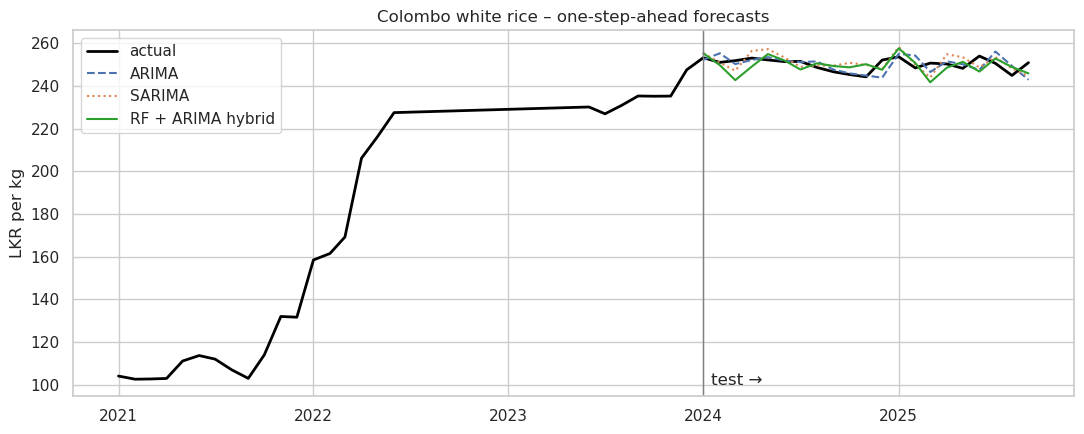

In [31]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(np.exp(ly["2021-01-01":]), color="black", lw=2, label="actual")
ax.plot(np.exp(arima_fc), ls="--", label="ARIMA")
ax.plot(np.exp(sarima_fc), ls=":", label="SARIMA")
ax.plot(np.exp(hybrid_fc), color="#2ca02c", label="RF + ARIMA hybrid")
ax.axvline(pd.Timestamp("2024-01-01"), color="grey", lw=1)
ax.text(pd.Timestamp("2024-01-15"), ax.get_ylim()[0] + 5, "test →")
ax.set_ylabel("LKR per kg")
ax.set_title("Colombo white rice – one-step-ahead forecasts")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "rice_forecast.png", dpi=120)
plt.show()

**Rice result:** the naive forecast was best (MAE about Rs 2.8, MAPE 1.1 %), with ARIMA(1,1,0) very close (Rs 3.0). SARIMA, the RF + ARIMA hybrid and lag-feature RF were
worse (Rs 3.8–4.0). Why: after the crisis, rice settled at about Rs 250/kg and stayed flat through 2024–25 (stable supply, partly helped by gazetted maximum retail prices), so there was
almost nothing left to forecast. The models learned from the volatile 2008 and 2022 periods and expected more movement than happened. **Lesson:** a hybrid only helps when the
residuals have a pattern; on a calm, flat series a simple model is the right choice.

## 11. Model comparison (2025 test set, LKR)

In [32]:
comp = pd.DataFrame(results)
naive_mae = comp.loc[0, "MAE"]
naive_rmse = comp.loc[0, "RMSE"]

# % improvement over the naive forecast (positive = better than naive)
comp["MAE vs naive"] = ((naive_mae - comp["MAE"]) / naive_mae * 100).round(2).astype(str) + " %"
comp["RMSE vs naive"] = ((naive_rmse - comp["RMSE"]) / naive_rmse * 100).round(2).astype(str) + " %"
comp = comp.sort_values("MAE").reset_index(drop=True)

best_name = comp.loc[comp["Family"] != "Baseline", "Model"].iloc[0]
print("Best model (lowest test MAE):", best_name)
comp.to_csv(REPORTS / "model_comparison.csv", index=False)
comp.round({"MAE": 2, "RMSE": 2, "R2": 4, "MAPE_%": 2, "Train time (s)": 1})

Best model (lowest test MAE): Stacking (RF+XGB+LGBM+Cat → Ridge)


,Model,Family,MAE,RMSE,R2,MAPE_%,Train time (s),MAE vs naive,RMSE vs naive
0,Stacking (RF+XGB+LGBM+Cat → Ridge),Stacking,63.01,103.65,0.9748,11.86,108.5,3.68 %,7.61 %
1,RF + ANN blend (w=0.95),Hybrid,65.28,107.31,0.9729,12.06,48.1,0.2 %,4.34 %
2,Naive (last month),Baseline,65.41,112.19,0.9704,12.19,0.0,0.0 %,0.0 %
3,LightGBM,Boosting,65.46,106.85,0.9732,12.22,22.9,-0.07 %,4.75 %
4,Random Forest,Bagging,65.64,107.96,0.9726,12.10,87.3,-0.35 %,3.76 %
5,CatBoost,Boosting,65.87,108.85,0.9722,12.20,88.6,-0.7 %,2.97 %
6,XGBoost,Boosting,66.11,109.76,0.9717,12.15,41.7,-1.07 %,2.16 %
7,Bagging (decision trees),Bagging,67.18,111.43,0.9708,12.66,10.7,-2.7 %,0.68 %
8,Extra Trees,Bagging,68.99,112.73,0.9701,12.97,2.9,-5.47 %,-0.49 %
9,RF + ANN residual hybrid,Hybrid,79.17,123.63,0.9641,15.60,31.1,-21.03 %,-10.2 %


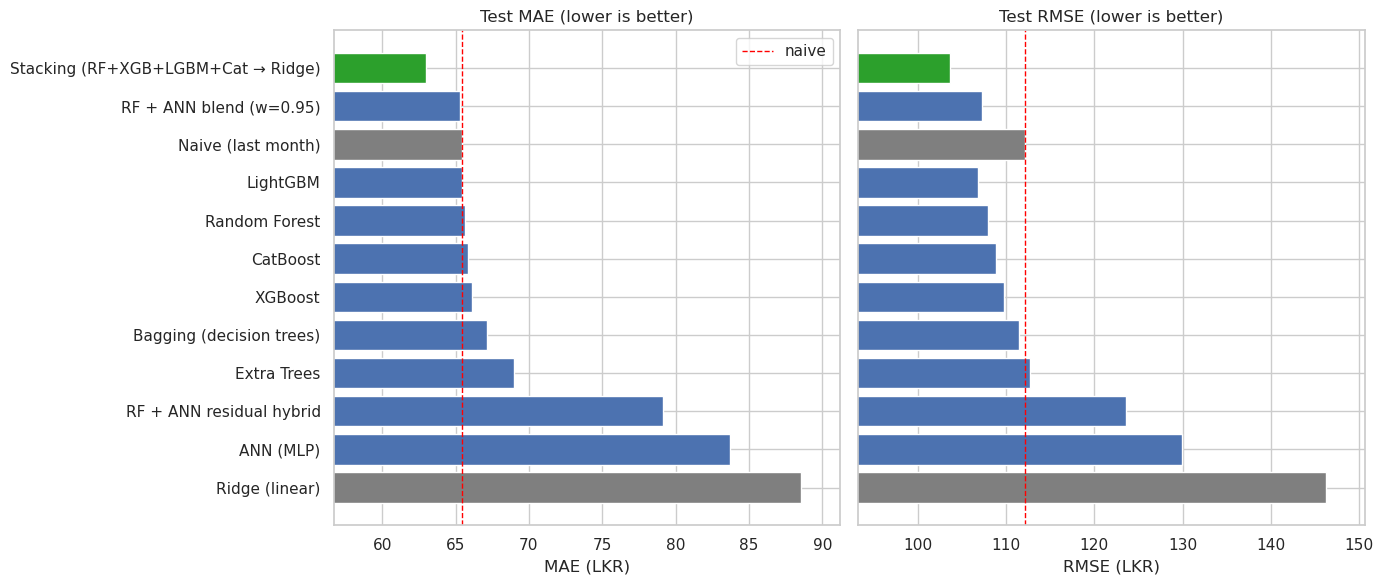

In [33]:
order = comp.sort_values("MAE", ascending=False)

# green = best model, grey = baselines, blue = the rest
colors = []
for m in order["Model"]:
    if m == best_name:
        colors.append("#2ca02c")
    elif "Naive" in m or "Ridge" in m:
        colors.append("#7f7f7f")
    else:
        colors.append("#4C72B0")

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
axes[0].barh(order["Model"], order["MAE"], color=colors)
axes[0].axvline(naive_mae, color="red", ls="--", lw=1, label="naive")
axes[0].set_xlabel("MAE (LKR)")
axes[0].set_title("Test MAE (lower is better)")
axes[0].set_xlim(order["MAE"].min() * 0.9, order["MAE"].max() * 1.03)
axes[0].legend()

axes[1].barh(order["Model"], order["RMSE"], color=colors)
axes[1].axvline(naive_rmse, color="red", ls="--", lw=1)
axes[1].set_xlabel("RMSE (LKR)")
axes[1].set_title("Test RMSE (lower is better)")
axes[1].set_xlim(order["RMSE"].min() * 0.9, order["RMSE"].max() * 1.03)

plt.tight_layout()
plt.savefig(FIG / "model_comparison.png", dpi=120)
plt.show()

### Error by food category (MAE, LKR)

In [34]:
by_cat = pd.DataFrame({"category": test["category"].astype(str)})
for m in ["Naive (last month)", "Random Forest", "XGBoost", "LightGBM", "CatBoost", best_name]:
    by_cat[m] = np.abs(test_preds[m] - y_test_price)

cat_table = by_cat.groupby("category").mean().round(1)
cat_table.insert(0, "rows", by_cat.groupby("category").size())
cat_table

,rows,Naive (last month),Random Forest,XGBoost,LightGBM,CatBoost,Stacking (RF+XGB+LGBM+Cat → Ridge)
category,,,,,,,
cereals and tubers,1042,10.5,12.0,13.7,11.2,12.8,11.1
"meat, fish and eggs",2695,95.8,92.7,96.4,96.1,95.3,91.5
miscellaneous food,306,31.7,39.7,40.2,38.4,37.2,35.0
pulses and nuts,1188,49.7,67.8,57.9,56.1,55.3,52.6
vegetables and fruits,3830,66.5,62.6,63.7,63.7,65.2,62.6


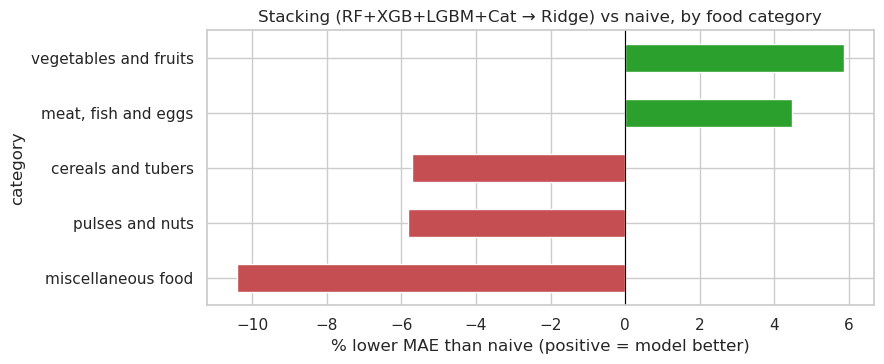

In [35]:
naive_col = cat_table["Naive (last month)"]
gain = ((naive_col - cat_table[best_name]) / naive_col * 100).sort_values()

colors = ["#C44E52" if v < 0 else "#2ca02c" for v in gain]
ax = gain.plot.barh(figsize=(9, 3.8), color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("% lower MAE than naive (positive = model better)")
ax.set_title(f"{best_name} vs naive, by food category")
plt.tight_layout()
plt.savefig(FIG / "gain_by_category.png", dpi=120)
plt.show()

### When does the model help? Big price moves vs small moves

In [36]:
# split the test rows into big moves (price changed more than 20 %) and small moves
change = np.abs(y_test_price / test["lag_1"].values - 1)
moves = pd.DataFrame({
    "move": np.where(change > 0.20, "big move (> 20 %)", "small move (≤ 20 %)"),
    "naive_error": np.abs(test_preds["Naive (last month)"] - y_test_price),
    "model_error": np.abs(test_preds[best_name] - y_test_price),
})
move_table = moves.groupby("move").agg(rows=("naive_error", "size"),
                                      naive_MAE=("naive_error", "mean"),
                                      model_MAE=("model_error", "mean")).round(1)
improvement = (move_table["naive_MAE"] - move_table["model_MAE"]) / move_table["naive_MAE"] * 100
move_table["model better by"] = improvement.round(1).astype(str) + " %"
move_table

,rows,naive_MAE,model_MAE,model better by
move,,,,
big move (> 20 %),1550,176.2,139.0,21.1 %
small move (≤ 20 %),7511,42.5,47.3,-11.3 %


### Actual vs predicted (best model) and example forecasts

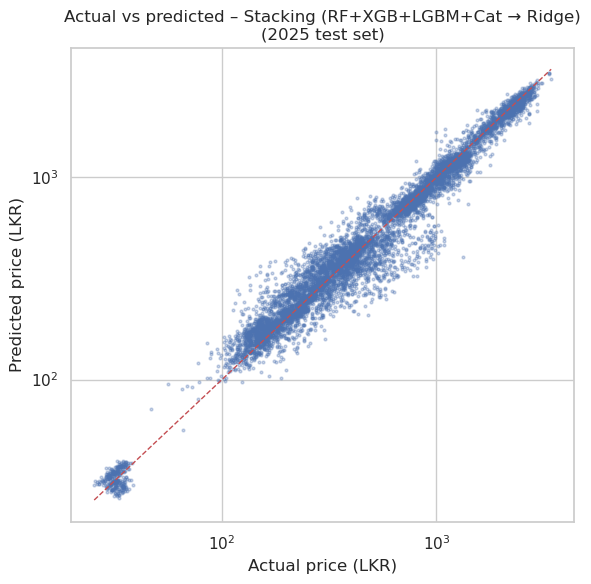

In [37]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test_price, test_preds[best_name], s=4, alpha=0.3)
low, high = y_test_price.min(), y_test_price.max()
ax.plot([low, high], [low, high], "r--", lw=1)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Actual price (LKR)")
ax.set_ylabel("Predicted price (LKR)")
ax.set_title(f"Actual vs predicted – {best_name}\n(2025 test set)")
plt.tight_layout()
plt.savefig(FIG / "actual_vs_predicted.png", dpi=120)
plt.show()

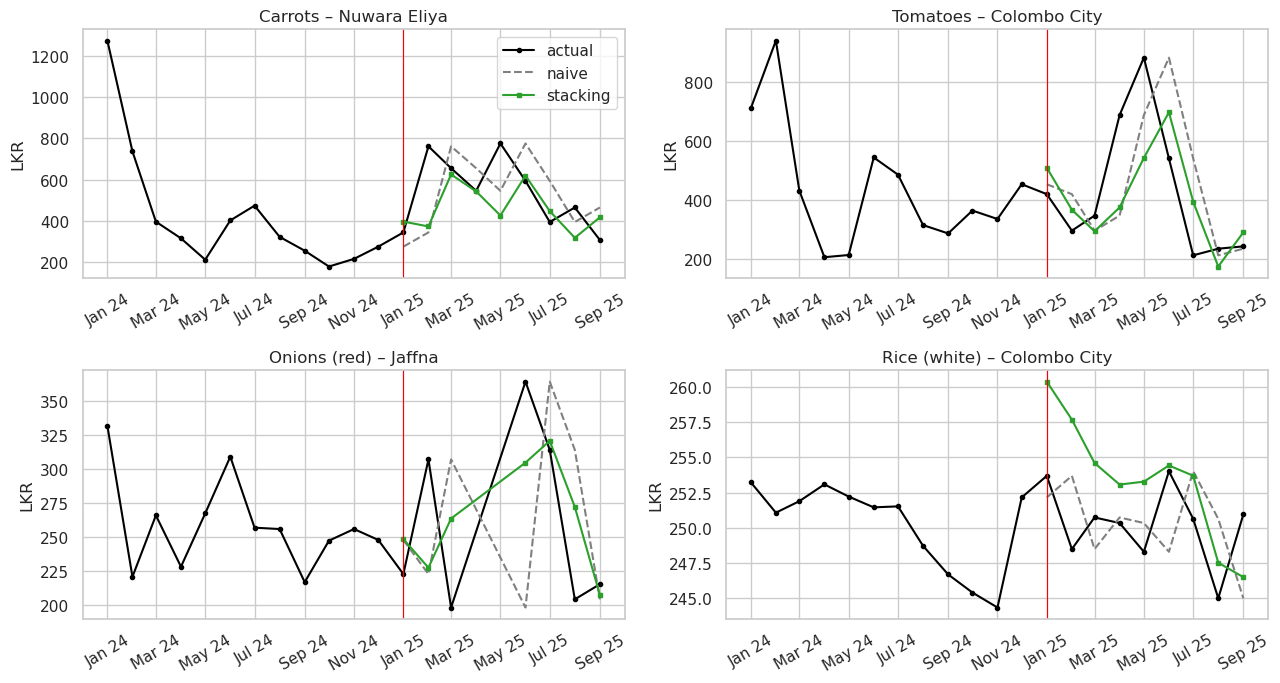

In [38]:
# a few market / item pairs to see what the forecasts look like
examples = [("Nuwara Eliya", "Carrots"), ("Colombo City", "Tomatoes"),
            ("Jaffna", "Onions (red)"), ("Colombo City", "Rice (white)")]

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, (mk, item) in zip(axes.ravel(), examples):
    hist = clean_df[(clean_df["market"] == mk) & (clean_df["commodity"] == item) & (clean_df["month"] >= "2024-01-01")]
    sel = ((test["market"] == mk) & (test["commodity"] == item)).values
    ax.plot(hist["month"], hist["price"], color="black", marker="o", ms=3, label="actual")
    ax.plot(test.loc[sel, "month"], test_preds["Naive (last month)"][sel], ls="--", color="grey", label="naive")
    ax.plot(test.loc[sel, "month"], test_preds[best_name][sel], color="#2ca02c", marker="s", ms=3, label="stacking")
    ax.axvline(pd.Timestamp("2025-01-01"), color="red", lw=0.8)
    ax.set_title(f"{item} – {mk}")
    ax.set_ylabel("LKR")
    ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%b %y"))
    ax.tick_params(axis="x", rotation=30)

axes[0, 0].legend()
plt.tight_layout()
plt.savefig(FIG / "example_forecasts.png", dpi=120)
plt.show()

### Which model won and why
* **Best model: Stacking (RF + XGBoost + LightGBM + CatBoost → Ridge).** On the 2025 test set it has the lowest MAE (Rs 63.0), RMSE (Rs 103.7) and MAPE (11.9 %),
  and it is the only model that beats the naive "same as last month" forecast on **every** metric (MAE 3.7 % lower, RMSE 7.6 % lower).
* **Why stacking won:** each single model makes different mistakes. The Ridge meta-model learned to rely mostly on **LightGBM and CatBoost**
  (the two with native categorical handling) and to give RF and XGBoost small negative weights, which corrects their shared errors. Averaging different views reduces variance.
* **RF vs gradient boosting:** among single models, LightGBM has the lowest RMSE (106.9), followed by RF (108.0), CatBoost (108.9) and XGBoost (109.8). MAE is almost a tie (65.5–66.1).
  LightGBM also trained about 4x faster than RF. Boosting wins slightly because it reduces bias step by step and its Huber loss is less affected by extreme price spikes.
* **Where the model helps:** on months with **big price moves (> 20 %)** the best model's error is about 21 % lower than naive, especially for upcountry vegetables
  (carrots, tomatoes) and red onions. On **stable items** (rice, lentils, eggs) naive is almost perfect and the model adds small noise.
  So the model is most useful exactly where shoppers and traders need it: volatile foods.
* **Hybrids:** the RF + ANN **residual** hybrid was worse than RF alone: the MLP could not find a pattern in RF's errors and added noise. The weighted blend chose 95 % RF on training data,
  which confirms the ANN adds little on this tabular data. Tree ensembles beat neural networks here.
* **R² is not useful for ranking** here (about 0.97 for every model, even naive) because prices range from Rs 20 to Rs 3,000; MAE and "vs naive" are the fair comparison.

### Save models and results for the dashboard

In [39]:
# save every trained model so the dashboard can load them without retraining
save = {"ridge": ridge, "random_forest": rf, "bagging": bag, "extra_trees": et, "xgboost": xgb,
        "lightgbm": lgbm, "catboost": cat, "stacking": stack, "ann": ann,
        "rf_ann_hybrid": hybrid, "rf_ann_blend": blend}
for file_name, m in save.items():
    joblib.dump(m, MODELS / f"{file_name}.joblib", compress=3)

# model name -> file name (results[0] is the naive baseline, which has no file)
name_to_file = {}
for row, file_name in zip(results[1:], save.keys()):
    name_to_file[row["Model"]] = file_name

meta = {"features": FEATURES, "cat_cols": CAT_COLS, "num_cols": NUM_COLS, "categories": CATEGORIES,
        "best_model": best_name, "model_files": name_to_file}
with open(MODELS / "meta.json", "w") as f:
    json.dump(meta, f, indent=2)

# test-set predictions of every model, for the dashboard charts
pred_df = test[["month", "market", "admin1", "admin2", "category", "commodity", "unit", "price"]].copy()
for name, pred in test_preds.items():
    pred_df[name] = pred
pred_df.to_csv(REPORTS / "test_predictions.csv", index=False)

total_mb = sum(p.stat().st_size for p in MODELS.glob("*.joblib")) / 1e6
print("Saved:", sorted(p.name for p in MODELS.glob("*")))
print(f"Total model size: {total_mb:.1f} MB")

Saved: ['ann.joblib', 'bagging.joblib', 'catboost.joblib', 'extra_trees.joblib', 'lightgbm.joblib', 'meta.json', 'random_forest.joblib', 'rf_ann_blend.joblib', 'rf_ann_hybrid.joblib', 'ridge.joblib', 'stacking.joblib', 'xgboost.joblib']
Total model size: 219.8 MB


## 12. Explainability: feature importance and SHAP
* **Built-in importance:** how much each feature reduces error inside the trees (RF, XGBoost, LightGBM gain, CatBoost), scaled to sum to 1.
* **SHAP (LightGBM):** for each prediction, how much each feature pushed the predicted % change up or down. LightGBM is used because it has the largest
  weight in the stacking meta-model and SHAP's TreeExplainer is exact and fast for it.

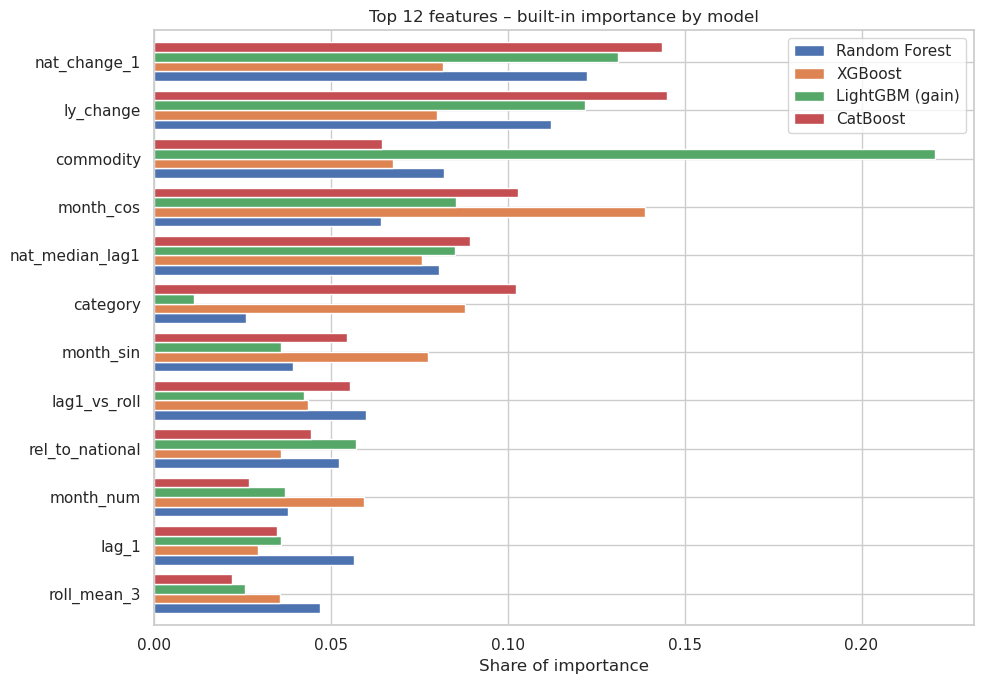

In [40]:
# built-in importance of each model, scaled so each column adds up to 1
def to_share(values):
    values = np.asarray(values, dtype=float)
    return values / values.sum()

imp = pd.DataFrame(index=FEATURES)
imp["Random Forest"] = to_share(rf.named_steps["model"].feature_importances_)
imp["XGBoost"] = to_share(xgb.named_steps["model"].feature_importances_)
imp["LightGBM (gain)"] = to_share(lgbm.booster_.feature_importance("gain"))
imp["CatBoost"] = to_share(cat.feature_importances_)
imp["Average"] = imp.mean(axis=1)
imp = imp.sort_values("Average", ascending=False)
imp.to_csv(REPORTS / "feature_importance.csv")

top = imp.head(12).drop(columns="Average")[::-1]
ax = top.plot.barh(figsize=(10, 7), width=0.8)
ax.set_xlabel("Share of importance")
ax.set_title("Top 12 features – built-in importance by model")
plt.tight_layout()
plt.savefig(FIG / "feature_importance.png", dpi=120)
plt.show()

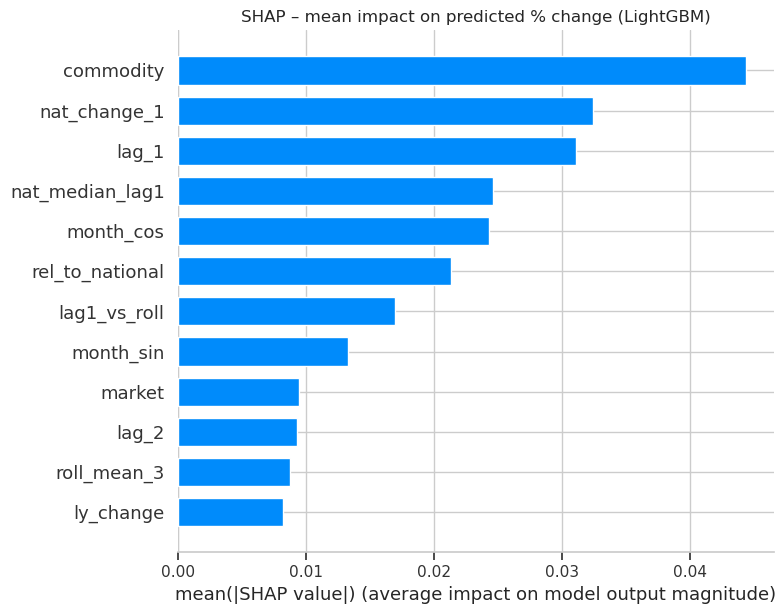

In [41]:
import shap

# SHAP on a sample of 2,000 test rows (enough for the plots, and much faster)
X_shap = X_test.sample(2000, random_state=RANDOM_STATE)
explainer = shap.TreeExplainer(lgbm)
shap_values = explainer.shap_values(X_shap)

shap_imp = pd.Series(np.abs(shap_values).mean(axis=0), index=FEATURES).sort_values(ascending=False)
shap_imp.rename("mean_abs_shap").to_csv(REPORTS / "shap_importance.csv")

shap.summary_plot(shap_values, X_shap, plot_type="bar", max_display=12, show=False)
plt.title("SHAP – mean impact on predicted % change (LightGBM)")
plt.tight_layout()
plt.savefig(FIG / "shap_bar.png", dpi=120)
plt.show()

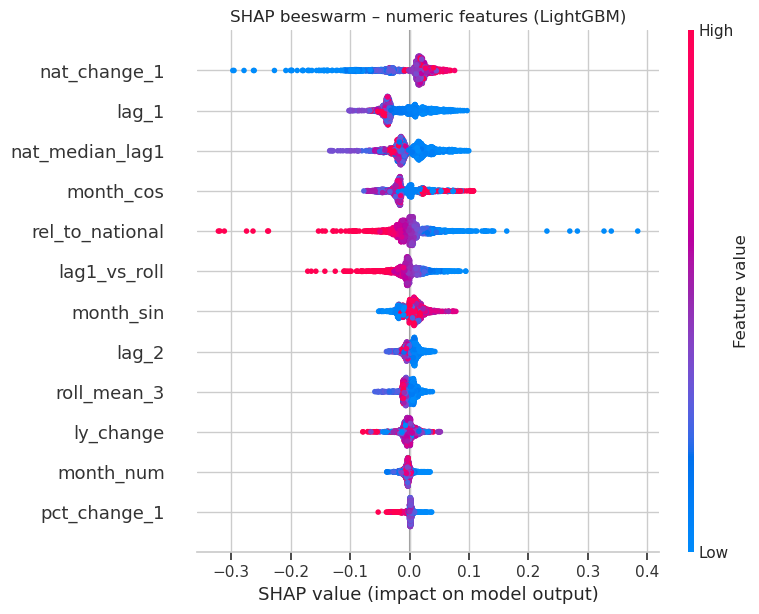

In [42]:
# the beeswarm colours only work for numeric columns, so I leave the category columns out here
num_idx = [FEATURES.index(c) for c in NUM_COLS]
shap.summary_plot(shap_values[:, num_idx], X_shap[NUM_COLS], max_display=12, show=False)
plt.title("SHAP beeswarm – numeric features (LightGBM)")
plt.tight_layout()
plt.savefig(FIG / "shap_beeswarm.png", dpi=120)
plt.show()

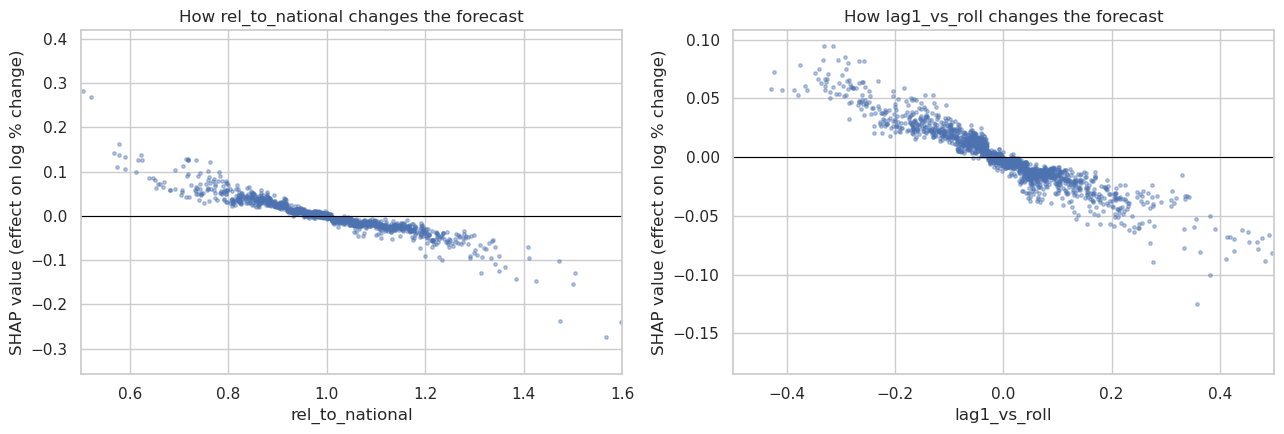

commodity          0.0444
nat_change_1       0.0325
lag_1              0.0311
nat_median_lag1    0.0246
month_cos          0.0243
rel_to_national    0.0213
lag1_vs_roll       0.0169
month_sin          0.0133
market             0.0094
lag_2              0.0093


In [43]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, feature in zip(axes, ["rel_to_national", "lag1_vs_roll"]):
    i = FEATURES.index(feature)
    ax.scatter(X_shap[feature], shap_values[:, i], s=6, alpha=0.4)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel(feature)
    ax.set_ylabel("SHAP value (effect on log % change)")
    ax.set_title(f"How {feature} changes the forecast")

axes[0].set_xlim(0.5, 1.6)
axes[1].set_xlim(-0.5, 0.5)
plt.tight_layout()
plt.savefig(FIG / "shap_dependence.png", dpi=120)
plt.show()

print(shap_imp.head(10).round(4))

### What the model learned, in Sri Lankan terms
* **Prices return to the national level (`rel_to_national`).** When a market was about 5 % *cheaper* than the national median last month, the model predicts a rise
  (average SHAP about +4 %); when it was about 5 % *dearer*, it predicts a fall (about −3 %). Markets are linked through wholesale hubs like Dambulla and Manning Market,
  so local price gaps close quickly.
* **Spikes fade (`lag1_vs_roll`).** If last month's price was above its own 3-month average, the model expects it to come down, and the other way round.
* **National momentum (`nat_change_1`).** If the national price of an item fell more than about 6 % last month, the model expects it to keep falling; a national rise pushes forecasts up.
  Supply shocks (rain in the hill country, import changes) hit all markets together.
* **Which item it is (`commodity`)** matters most overall: each food has its own trend in 2023–25 (for example pumpkin, eggs and bananas were pushed down, beans and pineapples up).
* **Season (`month_sin`, `month_cos`)** captures the year-end rise and the March/August harvest falls seen in the EDA.
* **Location columns (province, district, lat/lon) matter little** once `rel_to_national` is known: *how dear the market already is* tells the model more than *where it is*.
* `ly_change` (last year's move) ranks high in built-in gain importance but lower in SHAP. Gain counts how often a feature is used to split; SHAP measures its real effect on predictions,
  so SHAP is the more trustworthy view.

## 13. Research discussion
### 13.1 Random Forest vs gradient boosting (XGBoost, LightGBM, CatBoost)

In [44]:
rf_vs_gb = comp[comp["Model"].isin(["Random Forest", "XGBoost", "LightGBM", "CatBoost"])]
rf_vs_gb = rf_vs_gb[["Model", "MAE", "RMSE", "MAPE_%", "Train time (s)"]].sort_values("RMSE").reset_index(drop=True)
rf_vs_gb.round(2)

,Model,MAE,RMSE,MAPE_%,Train time (s)
0,LightGBM,65.46,106.85,12.22,22.9
1,Random Forest,65.64,107.96,12.10,87.3
2,CatBoost,65.87,108.85,12.20,88.6
3,XGBoost,66.11,109.76,12.15,41.7


| | **Random Forest (bagging)** | **Gradient boosting (XGBoost, LightGBM, CatBoost)** |
|---|---|---|
| **How trees are built** | Many deep trees built **independently, in parallel**, each on a bootstrap sample with random feature subsets; predictions are averaged. | Shallow trees built **one after another**; each new tree is fitted to the errors (gradients) of the trees so far. |
| **What it reduces** | **Variance**: averaging many noisy trees gives a stable model. | **Bias**: each step corrects what the model still gets wrong. |
| **Speed** | Easy to parallelise, but deep trees are slow and large (our RF: about 88 s including tuning, about 31 MB on disk). | LightGBM is the fastest here (about 23 s incl. tuning) thanks to histogram binning and leaf-wise growth; XGBoost about 40 s; CatBoost about 89 s. |
| **Tuning effort** | Low: works well with defaults; main knobs are `max_features` and `min_samples_leaf`. | Higher: learning rate, number of trees, depth/leaves, subsampling and loss all interact. |
| **Overfitting risk** | Low: more trees never hurt; deep trees are averaged out. | Higher: too many trees or a high learning rate memorise noise, so you need early stopping, regularisation or CV. |
| **Categorical features** | sklearn needs encoding (we used ordinal codes). | **CatBoost**: built-in ordered target statistics; **LightGBM**: native optimal category splits; **XGBoost**: needs encoding (or its experimental categorical mode). |
| **Robust loss** | Squared error (absolute error is very slow in sklearn). | Easy to switch to absolute / Huber loss, which helps with price spikes (LightGBM picked Huber). |

**Which wins on our data and why?** The four models are very close (MAE Rs 65.5–66.1). **LightGBM has the lowest RMSE (106.9)** and is the fastest, so it is the best
single model. Boosting edges out RF because (1) food price changes depend on interactions like *item × season × how dear the market is*, which boosting learns step by step,
(2) its Huber loss is not dragged around by extreme vegetable spikes, and (3) LightGBM and CatBoost handle the 36 markets and 33 items as true categories. RF is a close
second with almost no tuning, so it remains a strong, safe default. The **stacked combination beat all of them**, which shows that RF and the boosters make *different*
errors, and blending them is more valuable than picking one winner.

### 13.2 Strengths and limitations of tree ensembles: tabular data vs image / text data
**On tabular data (like ours), tree ensembles are usually the best choice:**
* They handle **mixed feature types** (prices, ratios, months, market names) with little preprocessing, and no scaling.
* They capture **non-linear effects and interactions** automatically (e.g. carrots in Nuwara Eliya in December).
* They are **robust to outliers and irrelevant features**, and boosting libraries handle **missing values** natively.
* They train fast on CPUs, need little data compared with deep learning, and are **explainable** with feature importance and SHAP.
* Benchmarks agree: tree ensembles still beat deep learning on typical tabular datasets (Grinsztajn et al., 2022). Our results match this: the MLP (ANN) was the weakest non-linear model.

**Limitations on tabular data:** trees **cannot extrapolate** beyond values seen in training (that is why we predict the % change instead of the price level),
they do not understand time order by themselves (we had to build lag features), and big forests can be large and slow to load.

**On image and text data, tree ensembles are weak:**
* An image is thousands of raw pixels whose meaning comes from **spatial patterns** (edges, shapes). Trees split on one pixel at a time and cannot learn
  these patterns; **CNNs and vision transformers** do this far better.
* Text meaning depends on **word order and context**. Trees on bag-of-words / TF-IDF features ignore order and struggle with very high-dimensional sparse data;
  **transformer models (e.g. BERT)** are much stronger.
* Ensembles still help in a supporting role: gradient boosting on **features extracted by a neural network** (image embeddings, sentence embeddings), or as a fast baseline
  for simple text classification.

**Summary:** structured rows and columns → tree ensembles (bagging / boosting / stacking); raw pixels, audio or language → deep learning, possibly with an ensemble on top.

## 14. Dashboard (Streamlit)
**🔗 Live dashboard (no install needed):** [https://kademila.streamlit.app](https://kademila.streamlit.app)

The dashboard is in **`app.py`** and loads the models and results saved above (`models/`, `reports/`), so it starts quickly and does not retrain anything.

```
streamlit run app.py        # opens http://localhost:8501
```

| Page | What it shows |
|---|---|
| Overview | Dataset size, sample rows, national price trends, **map of markets coloured by how dear they are vs the national median**, item volatility |
| Model comparison | Metrics table of all models (best marked 🏆), bar chart with selectable metric and the naive line, error by category |
| Model explorer | **Model selector** (all 12 models), actual vs predicted, 2025 forecast line for any market and item, % error per item |
| Explainability | Built-in feature importance per model, SHAP importance and dependence plots |
| Rice forecast | RF + ARIMA hybrid vs ARIMA, SARIMA and lag-RF on Colombo rice |
| Price check & forecast | **"Make a prediction" form**: choose market, item and model → next-month forecast in LKR with a typical range; enter a quoted price → *high / fair / low* verdict; what-if on last month's price |
| Early warning | Forecast for every market and item; lists those expected to rise or fall more than a chosen % next month, filter by province |

To run it on your own computer instead, install `requirements.txt` and use the command above.

## 15. Conclusion & limitations
**Conclusion**
* Using official WFP / DCS / HARTI market data, we forecast next month's retail price of 33 foods in 36 Sri Lankan markets with bagging, boosting, stacking and hybrid models.
* **Stacking (RF + XGBoost + LightGBM + CatBoost → Ridge) was the best model** (test MAE Rs 63.0, MAPE 11.9 %) and the only one that beat the naive "same as last month" forecast on every metric.
  Among single models, **LightGBM** was the most accurate (lowest RMSE) and fastest.
* Next month's price is mostly last month's price, but on **big price moves (> 20 %)**, the ones that hurt households most, the best model **cuts the error by about 21 %**,
  especially for upcountry vegetables and onions.
* SHAP shows the model learned real market behaviour: **local prices move back toward the national level, spikes fade, and national trends spread to all markets.**
* RF + ANN hybrids did not help: on tabular data, the neural network added noise. On Colombo rice, prices were flat after the crisis, so simple models (naive, ARIMA) were best.
* The **KadeMila dashboard** turns this into a practical tool: a price-fairness check for shoppers and an early-warning list for traders and aid programmes.

**Limitations**
* Wide market coverage only starts in **June 2023**, so models learn from about 1.5 years and are tested on one 9-month period; results could differ in another year.
* The data are **monthly survey averages**, not real shop quotes, and some months are missing (11 rice months were interpolated).
* No outside drivers yet: **rainfall, fuel prices, the exchange rate, import rules** strongly affect Sri Lankan food prices.
* sklearn stacking uses consecutive blocks for out-of-fold predictions, so some blocks are predicted by models that saw later months (a mild optimistic bias).
* The ANN was only lightly tuned; a better-tuned network might do better.

**Future improvements**
* Add Department of Meteorology rainfall, CBSL exchange rates and CEYPETCO fuel prices as features.
* **Smart switching:** use the ensemble for volatile items and the naive forecast for stable ones (rice, lentils), choosing per item with cross-validation.
* Prediction intervals with conformal prediction instead of the simple ± average-error band.
* Weekly HARTI price data, multi-month forecasts, and an SMS / WhatsApp price-check bot in **Sinhala and Tamil**.

## 16. References
1. World Food Programme (2025). *Sri Lanka – Food Prices* [dataset]. Humanitarian Data Exchange. https://data.humdata.org/dataset/wfp-food-prices-for-sri-lanka (sources: Department of Census and Statistics, HARTI, WFP).
2. Breiman, L. (1996). Bagging predictors. *Machine Learning*, 24(2), 123–140.
3. Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32.
4. Geurts, P., Ernst, D., & Wehenkel, L. (2006). Extremely randomized trees. *Machine Learning*, 63(1), 3–42.
5. Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *Annals of Statistics*, 29(5), 1189–1232.
6. Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of KDD 2016*, 785–794.
7. Ke, G., et al. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems 30*.
8. Prokhorenkova, L., et al. (2018). CatBoost: Unbiased boosting with categorical features. *Advances in Neural Information Processing Systems 31*.
9. Wolpert, D. H. (1992). Stacked generalization. *Neural Networks*, 5(2), 241–259.
10. Zhang, G. P. (2003). Time series forecasting using a hybrid ARIMA and neural network model. *Neurocomputing*, 50, 159–175.
11. Box, G. E. P., & Jenkins, G. M. (1970). *Time Series Analysis: Forecasting and Control*. Holden-Day.
12. Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems 30*.
13. Grinsztajn, L., Oyallon, E., & Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *NeurIPS 2022 Datasets and Benchmarks Track*.
14. Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.